# PPE compliance detection: analysis walk-through

**Stakeholder:** a site-safety officer reviewing camera footage. **Decision:** which photos need a human look
because gear appears to be missing. **Data:** a Roboflow-hosted, CC BY 4.0 dataset of real construction /
industrial photos, 10 classes: 5 gear-present (glove, goggles, helmet, mask, shoes) and their 5 "missing"
counterparts. Two Faster R-CNN (MobileNetV3 backbone) detectors, fine-tuned on CPU from COCO weights at two
input resolutions.

In [1]:
import json, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from IPython.display import Image
from ppedet import config, data

res = json.loads((config.ARTIFACTS / "results.json").read_text())
res["dataset"]["split_images"], res["dataset"]["distinct_images"], res["dataset"]["files_in_source"]

({'train': 4419, 'val': 632, 'test': 1263}, 6314, 11978)

## 1. The data problem that had to be fixed before any training

The dataset ships as three pre-made splits (train/valid/test), but they turned out to be unusable as-is:

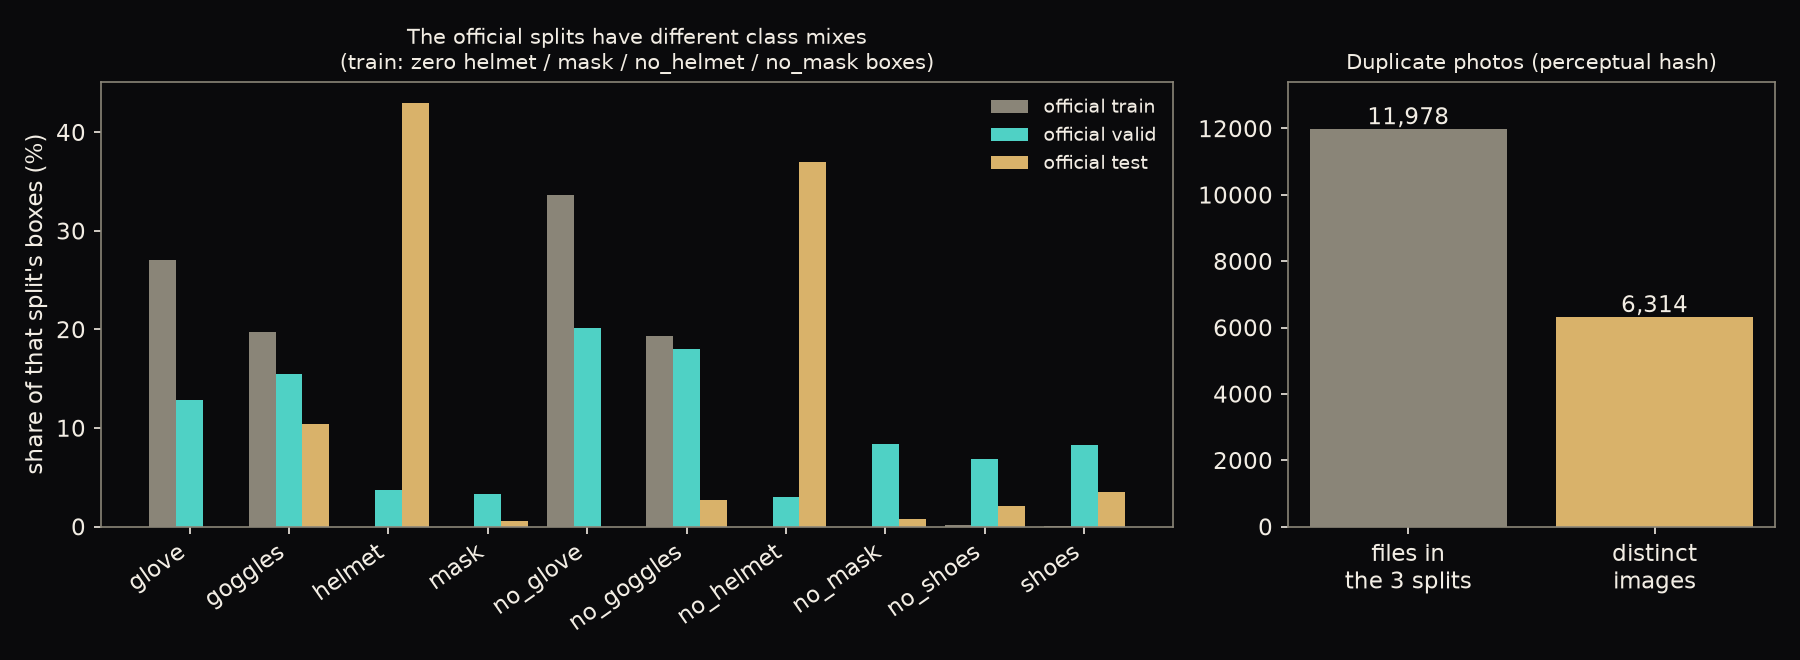

In [2]:
Image(str(config.FIGURES / "01_data_audit.png"))

The official **train** split has **zero** helmet, mask, no_helmet or no_mask boxes at all — every helmet
example was in valid/test. And the 11,978 files across the three splits reduce to only **6,314 distinct
images** by perceptual hash (dHash): hundreds of near-identical consecutive video frames were split across
train/valid/test, which would have let the model memorise a frame instead of learning to detect. **Fix:**
pool all three splits, drop exact duplicates, group near-duplicates (Hamming distance <= 1 on a 64-bit hash)
so a burst of frames stays on one side, then re-split 70/10/20 by whole group. See `data.make_splits()`.

## 2. Two models, two input resolutions, fine-tuned on CPU

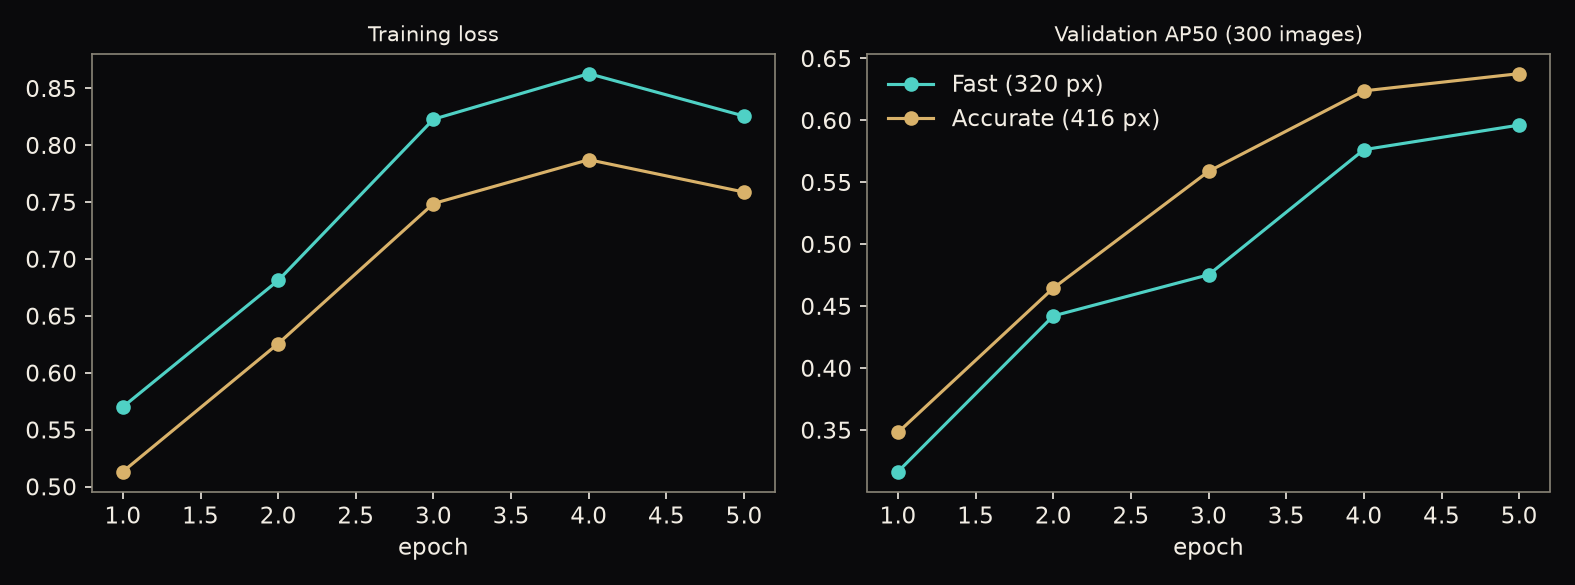

In [3]:
Image(str(config.FIGURES / "04_training.png"))

In [4]:
for k, m in res["models"].items():
    print(k, "val AP50 by epoch:", [round(h["val_ap50"], 3) for h in m["history"]])

fast val AP50 by epoch: [0.316, 0.442, 0.475, 0.576, 0.596]
accurate val AP50 by epoch: [0.348, 0.465, 0.559, 0.624, 0.638]


Both models improve steadily for all 5 epochs with no sign of overfitting yet (validation AP50 still rising
at the last epoch) — more epochs would likely help further; 5 was a time budget, not a plateau.

## 3. Held-out test results

In [5]:
rows = {k: {"mAP@[.5:.95]": m["coco"]["map"], "AP50": m["coco"]["ap50"],
           "mAP (6 well-covered classes)": m["coco"]["reliable_map"], "Precision": m["operating_point"]["micro"]["precision"],
           "Recall": m["operating_point"]["micro"]["recall"], "F1": m["operating_point"]["micro"]["f1"],
           "Latency (ms)": m["latency"]["median_ms"]} for k, m in res["models"].items()}
pd.DataFrame(rows).T.round(3)

,mAP@[.5:.95],AP50,mAP (6 well-covered classes),Precision,Recall,F1,Latency (ms)
fast,0.188,0.475,0.287,0.743,0.679,0.710,155.101
accurate,0.220,0.518,0.332,0.786,0.726,0.755,193.784


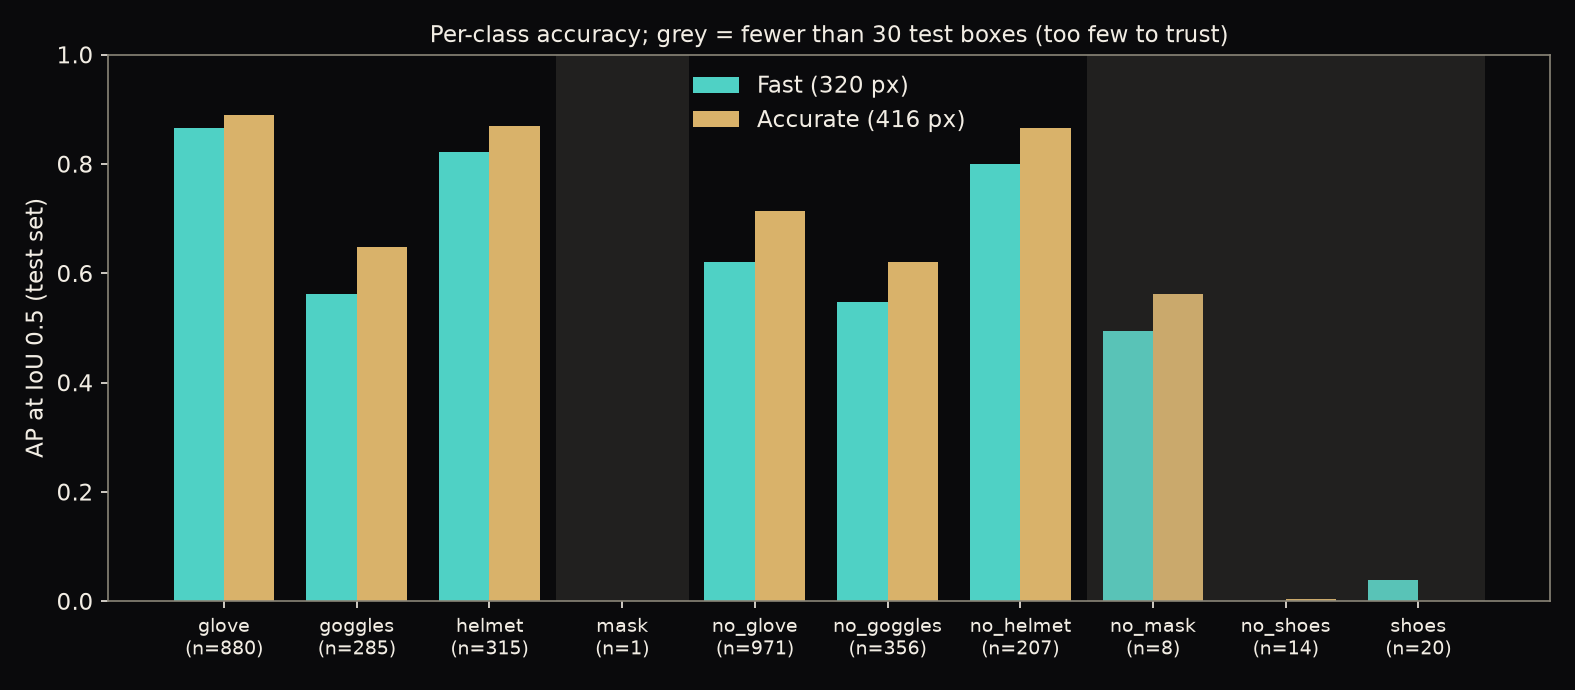

In [6]:
Image(str(config.FIGURES / "02_per_class_ap.png"))

**Honest read:** 6 of 10 classes have enough test boxes (>= 30) to trust their AP; on those, the accurate
model reaches **0.77 AP50**. The other 4 (mask, no_mask, no_shoes, shoes) have 1-20 test boxes each — too few
to report a meaningful AP, shown in grey and excluded from the "6 well-covered classes" headline number. This
is a direct result of the class imbalance baked into the source data (see the split audit above), not
something more training time fixes.

## 4. Where the accurate model actually goes wrong

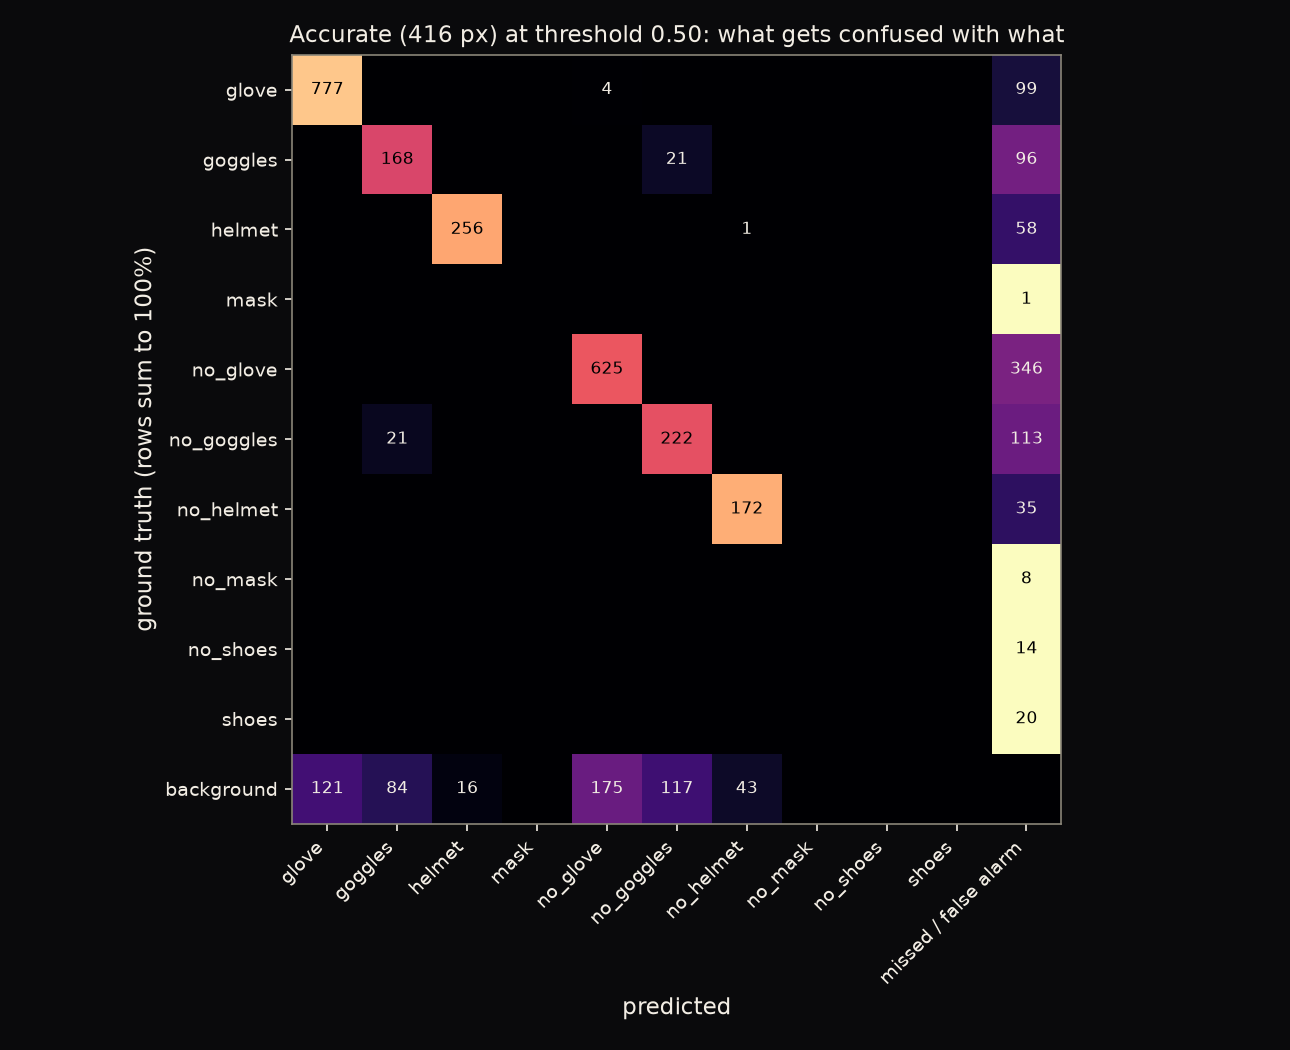

In [7]:
Image(str(config.FIGURES / "03_confusion.png"))

Most detections land on the diagonal (correct class). The two largest off-diagonal blocks are **goggles
predicted as no_helmet** (21 cases) and **no_glove predicted as no_goggles** (21 cases) — both look like the
model latching onto co-occurring context (a face region, a hand region) rather than the specific gear texture.
The single largest error mode by far, though, is the **missed/false-alarm column and row**: 346 missed
no_glove instances and 175 background regions mistaken for no_glove, both consistent with `no_glove` being
the single largest class in the data (highest raw count, but also highest opportunity for error).

## 5. Does test-time resolution matter?

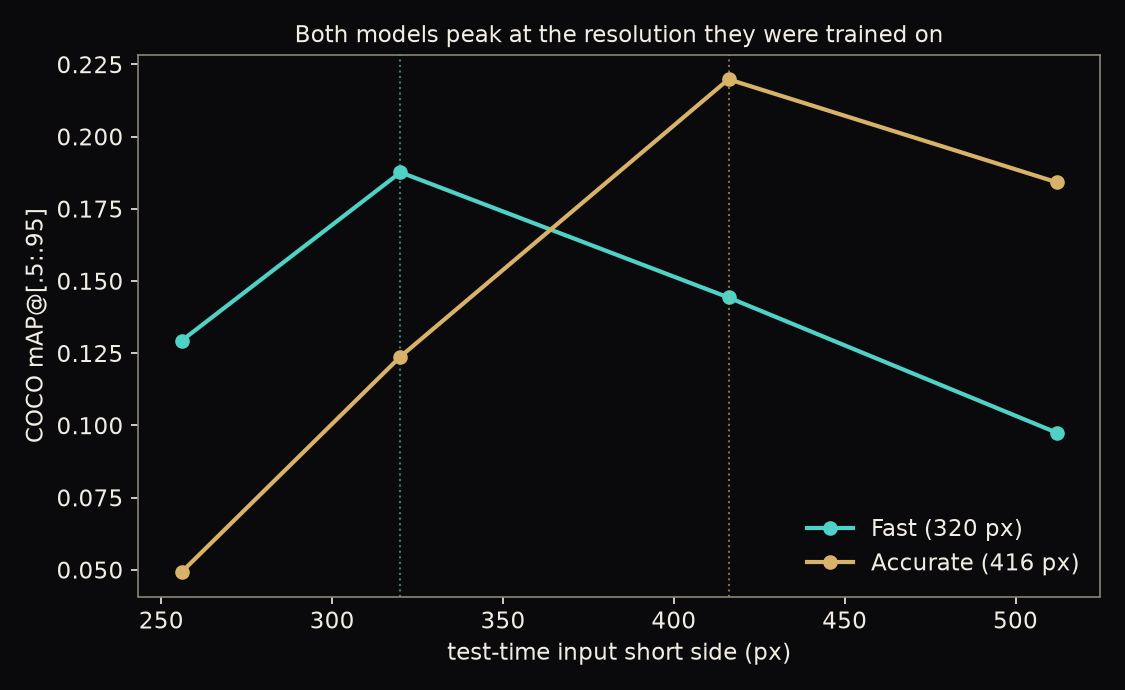

In [8]:
Image(str(config.FIGURES / "05b_size_sweep.png"))

Yes, sharply. Each model was tested at 4 input sizes using the SAME trained weights (no retraining) — both
peak almost exactly at the resolution they were fine-tuned on, and degrade in both directions. This rules out
"just run it bigger at inference time for free accuracy": these small anchor-free-ish detectors are tuned to
one scale.

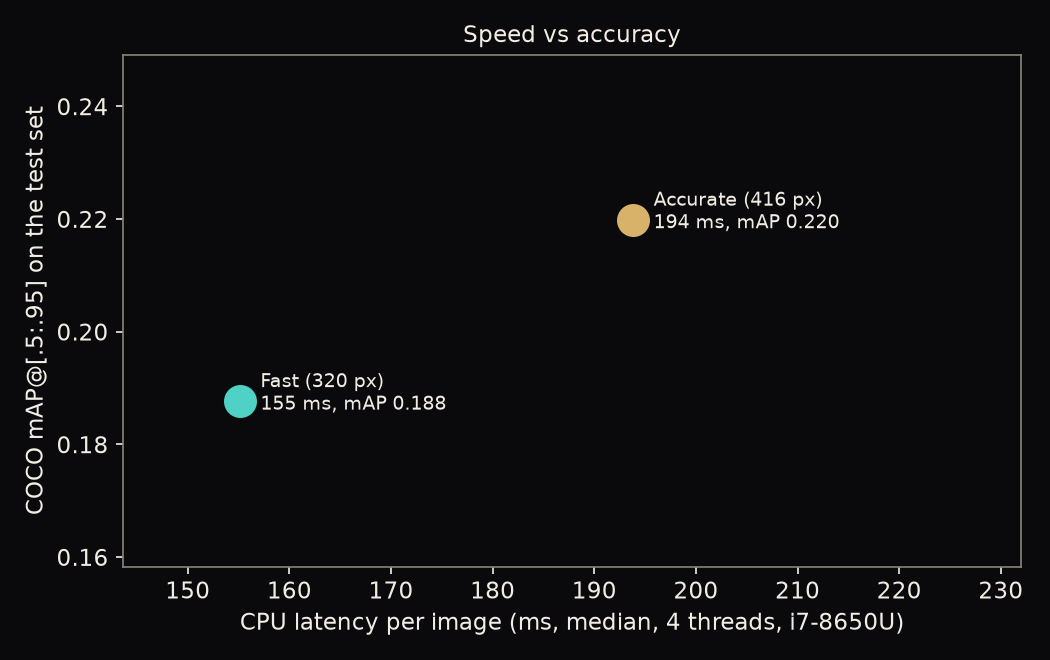

In [9]:
Image(str(config.FIGURES / "05_speed_accuracy.png"))

The accurate model costs **+25% latency** (194ms vs 155ms median, both single-threaded-equivalent on a
4-thread i7-8650U) for **+17% mAP** (0.220 vs 0.188) and **+9% AP50** (0.518 vs 0.475) — a real but modest
trade a deployer could reasonably make either way depending on whether the bottleneck is a live camera feed
(favour fast) or a batch review queue (favour accurate).

## 6. Random, non-cherry-picked examples

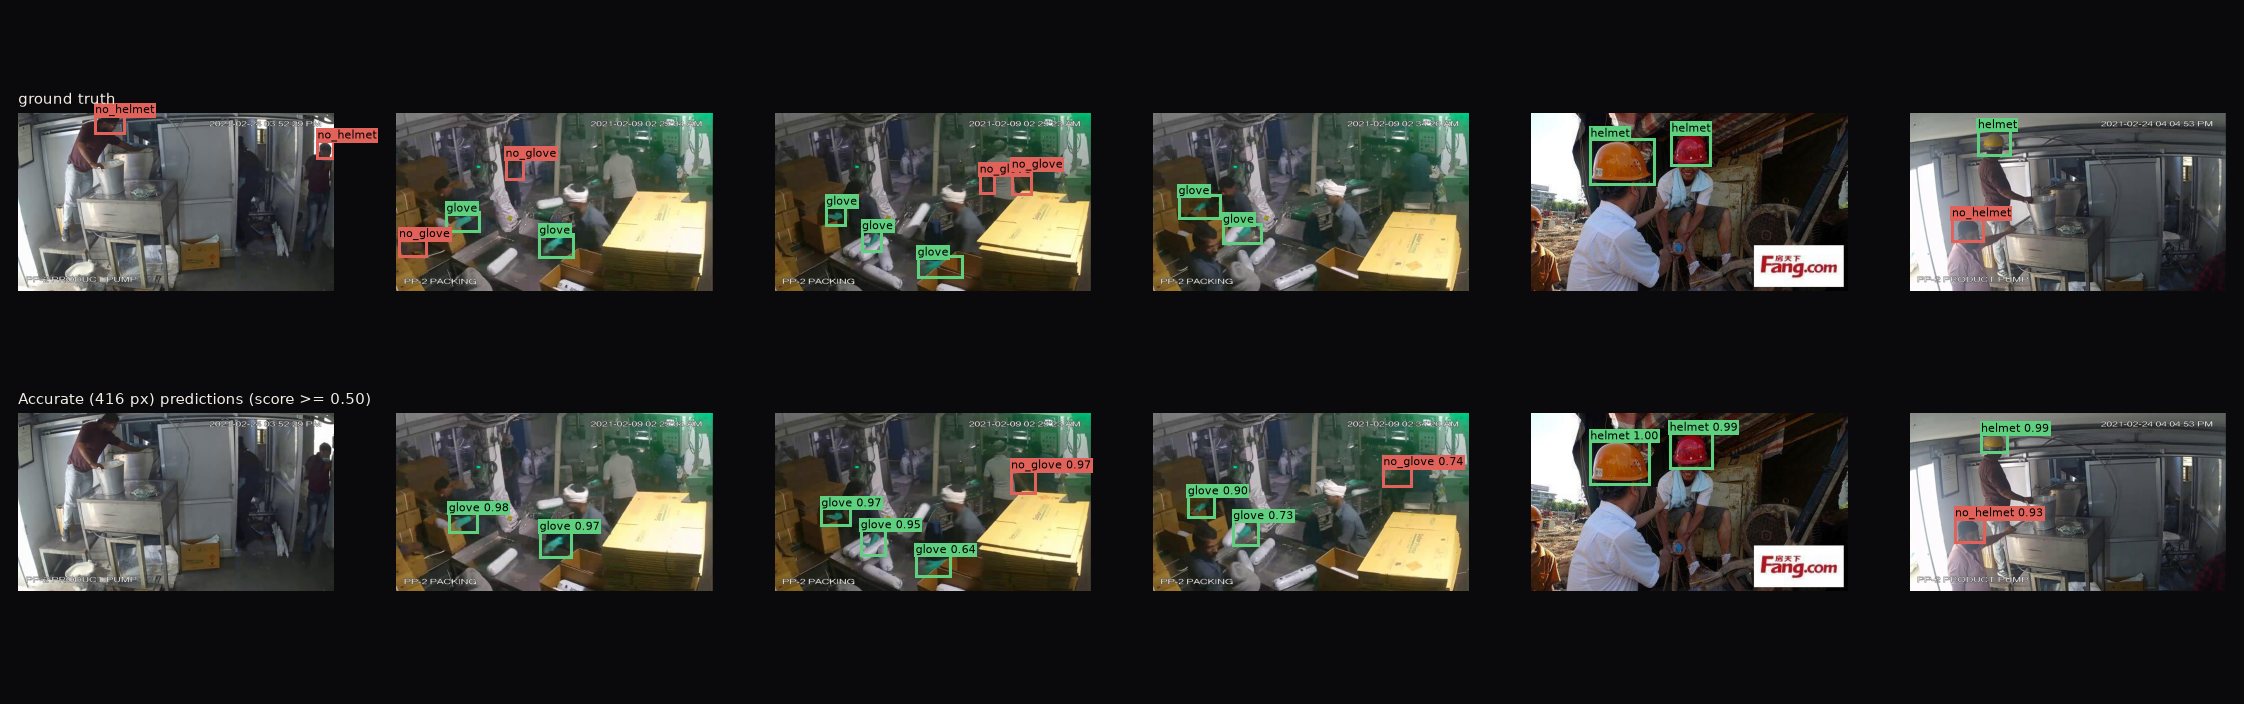

In [10]:
Image(str(config.FIGURES / "06_examples.png"))

Six test images chosen by a fixed random seed (not hand-picked for a good look). The model catches gloves,
goggles and helmets reliably; two of the no_helmet ground-truth boxes in the leftmost images are missed
entirely at threshold 0.50 — consistent with the confusion matrix's largest error mode being missed
detections on the harder, more visually ambiguous classes.